<a href="https://colab.research.google.com/github/iasd00022-lgtm/data-mining-adult-income/blob/iasd22-knn/03_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le dataset
df = pd.read_csv(r"adult.csv")

# Afficher les 5 premières lignes
df.head()


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [13]:
# Remplacer les "?" par des vraies valeurs manquantes (NaN)
# Attention : pas d'espace avant le ?, on cherche exactement ce qu'il y a dans le fichier
df = df.replace('?', np.nan)
# Remplacer par la valeur la plus fréquente (le mode) pour chaque colonne
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Vérifier s'il reste des valeurs manquantes
print("Valeurs manquantes restantes :", df.isnull().sum().sum())




Valeurs manquantes restantes : 0


In [14]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

df.head() # Tout doit être en chiffres maintenant

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,3,77053,11,9,6,9,1,4,0,0,4356,40,38,0
1,82,3,132870,11,9,6,3,1,4,0,0,4356,18,38,0
2,66,3,186061,15,10,6,9,4,2,0,0,4356,40,38,0
3,54,3,140359,5,4,0,6,4,4,0,0,3900,40,38,0
4,41,3,264663,15,10,5,9,3,4,0,0,3900,40,38,0


In [15]:
from sklearn.preprocessing import StandardScaler

X = df.drop('income', axis=1)
y = df['income']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

X.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,3.769612,-0.085296,-1.067997,0.181332,-0.420060,2.249480,0.720237,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-0.035429,0.26137
1,3.183112,-0.085296,-0.539169,0.181332,-0.420060,2.249480,-0.790092,-0.277805,0.393668,-1.422331,-0.14592,10.593507,-1.817204,0.26137
2,2.010110,-0.085296,-0.035220,1.214869,-0.031360,2.249480,0.720237,1.589322,-1.962621,-1.422331,-0.14592,10.593507,-0.035429,0.26137
3,1.130359,-0.085296,-0.468215,-1.368974,-2.363558,-1.734058,-0.034928,1.589322,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.26137
4,0.177296,-0.085296,0.709482,1.214869,-0.031360,1.585557,0.720237,0.966947,0.393668,-1.422331,-0.14592,9.461864,-0.035429,0.26137


In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)

Taille de X_train : (26048, 14)
Taille de X_test  : (6513, 14)


In [17]:
print(X_train.shape, X_test.shape)
print("Valeurs manquantes :", X_train.isna().sum().sum())
print("Types :", X_train.dtypes.unique())
print("Classes de y :", y_train.unique())

(26048, 14) (6513, 14)
Valeurs manquantes : 0
Types : [dtype('float64')]
Classes de y : [0 1]


In [18]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)
import matplotlib.pyplot as plt

print("Baseline (toujours <=50K) :", round(1 - y_test.mean(), 3))

Baseline (toujours <=50K) : 0.764


distance  euclidean  manhattan
k                             
3            0.6027     0.6041
5            0.6169     0.6201
7            0.6203     0.6239
11           0.6198     0.6316
15           0.6208     0.6299
21           0.6165     0.6286


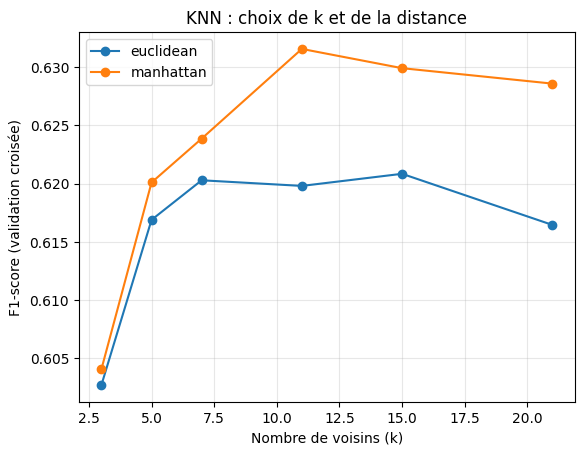

Meilleur réglage : 11 manhattan


In [19]:
resultats = []
for metric in ["euclidean", "manhattan"]:
    for k in [3, 5, 7, 11, 15, 21]:
        knn = KNeighborsClassifier(n_neighbors=k, metric=metric)
        f1 = cross_val_score(knn, X_train, y_train, cv=5, scoring="f1", n_jobs=-1).mean()
        resultats.append({"distance": metric, "k": k, "F1_cv": f1})

res = pd.DataFrame(resultats)
print(res.pivot(index="k", columns="distance", values="F1_cv").round(4))

for metric in ["euclidean", "manhattan"]:
    sous = res[res["distance"] == metric]
    plt.plot(sous["k"], sous["F1_cv"], marker="o", label=metric)
plt.xlabel("Nombre de voisins (k)")
plt.ylabel("F1-score (validation croisée)")
plt.title("KNN : choix de k et de la distance")
plt.legend(); plt.grid(alpha=0.3); plt.show()

meilleur = res.loc[res["F1_cv"].idxmax()]
best_k, best_metric = int(meilleur["k"]), meilleur["distance"]
print("Meilleur réglage :", best_k, best_metric)

Observation 1 : la distance de Manhattan est meilleure que l’euclidienne.

Pour presque toutes les valeurs de k, la distance de Manhattan donne un F1 supérieur à la distance euclidienne (par exemple 0,6316 contre 0,6198 pour k = 11). L’écart reste faible (environ 0,01), mais il est régulier. Manhattan est donc retenue.


Observation 2 : le F1 augmente avec k puis se stabilise, le meilleur réglage est k = 11 avec Manhattan.

Avec un petit k (k = 3), le F1 est le plus bas (0,6041 en Manhattan) : le modèle est sensible au bruit et risque de surapprendre. Le F1 progresse jusqu’à k = 11 (0,6316, maximum), puis redescend légèrement (0,6299 pour k = 15, 0,6286 pour k = 21). Le réglage retenu est donc k = 11 avec la distance de Manhattan, un compromis entre sensibilité au bruit et lissage excessif.

Accuracy : 0.8408
Precision : 0.6959
Recall   : 0.5777
F1-score : 0.6314
AUC-ROC  : 0.879
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      4976
        >50K       0.70      0.58      0.63      1537

    accuracy                           0.84      6513
   macro avg       0.79      0.75      0.76      6513
weighted avg       0.83      0.84      0.84      6513



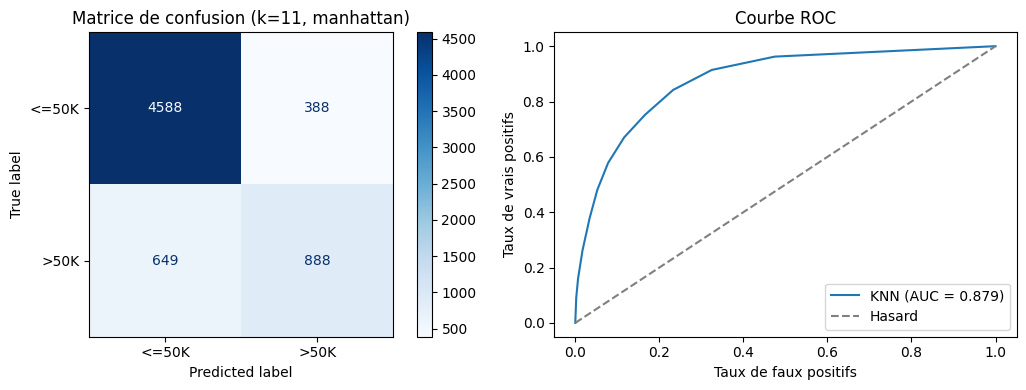

In [20]:
knn = KNeighborsClassifier(n_neighbors=best_k, metric=best_metric)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
y_proba = knn.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision :", round(precision_score(y_test, y_pred), 4))
print("Recall   :", round(recall_score(y_test, y_pred), 4))
print("F1-score :", round(f1_score(y_test, y_pred), 4))
print("AUC-ROC  :", round(roc_auc_score(y_test, y_proba), 4))
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=["<=50K", ">50K"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title(f"Matrice de confusion (k={best_k}, {best_metric})")
fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, label=f"KNN (AUC = {roc_auc_score(y_test, y_proba):.3f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray", label="Hasard")
axes[1].set_xlabel("Taux de faux positifs"); axes[1].set_ylabel("Taux de vrais positifs")
axes[1].set_title("Courbe ROC"); axes[1].legend()
plt.tight_layout(); plt.show()

Observation 1 : l’accuracy dépasse la baseline, mais l’apport reste modeste.

Le modèle atteint une accuracy de 0,8408, contre 0,764 pour le classifieur qui prédit toujours <=50K (4 976 sur 6 513). Le gain est d’environ 7 points. L’accuracy seule est trompeuse à cause du déséquilibre des classes : il faut regarder les métriques de la classe minoritaire.

Observation 2 : la classe >50K est moins bien détectée que la classe <=50K.

Pour <=50K, le recall est de 0,92 et la precision de 0,88. Pour >50K, le recall tombe à 0,58 : le modèle ne retrouve qu’environ 58 % des personnes à revenu élevé, et la moitié environ de ses erreurs sont des >50K classés à tort en <=50K. Le F1 de cette classe est de 0,63. Cela confirme l’effet du déséquilibre (76 % / 24 %), qui justifie le traitement par rééquilibrage (travail d’IASD03).

Observation bonus sur l’AUC

L’AUC-ROC de 0,879 montre que le modèle sépare plutôt bien les deux classes lorsqu’on varie le seuil de décision. Le recall de la classe >50K pourrait être amélioré en abaissant le seuil de 0,5, au prix d’une baisse de la precision.